
#SI LAB PROJECT
#Topic:Regression :Smart Phone Price Prediction
#Name:Aastha Goyanka
#Section:B2
#Roll no:01




Topic: Regression – Smart Phone Price Prediction

The aim of this project is to predict smartphone prices using machine learning regression techniques. Smartphone pricing data is collected through web scraping, cleaned, and analyzed to identify pricing patterns. Regression algorithms such as Linear Regression, Ridge, Lasso, Decision Tree, and Random Forest are implemented and compared to select the best-performing model. The system provides a user-friendly interface using Gradio and Streamlit, allowing users to enter an old smartphone price and predict its revised price.

In [3]:
#Import Libraries
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np

In [4]:
#Web Scraping the Website
url = "https://gadgets.beebom.com/guides/india-smartphone-price-hike-roundup"

response = requests.get(url)

soup = BeautifulSoup(response.text, "html.parser")

response.status_code

200

In [5]:
soup.title.text

'India Smartphone Price Hike Tracker: List of Phones with Revised Prices (Updated September 2026) | Beebom Gadgets'

In [6]:
#Extract All Tables from the Beebom Website
tables = soup.find_all("table")

len(tables)

13

In [7]:
tables[0].get_text(" ", strip=True)

'Model Old Price (Rs) New Price (Rs) Samsung Galaxy A06 5G 10,499 12,499 Samsung Galaxy A07 4G 13,899 16,999 Samsung Galaxy A17 5G 18,999 20,499 Samsung Galaxy M47 32,999 35,999 Samsung Galaxy A36 5G 32,499 33,999 Samsung Galaxy A37 5G 43,999 46,999 Samsung Galaxy A56 5G 40,999 42,999 Samsung Galaxy A57 5G 67,499 72,499 Samsung Galaxy M06 5G 9,999 12,000 Samsung Galaxy M07 6,999 9,999 Samsung Galaxy M17 5G 12,499 16,499 Samsung Galaxy M17E 13,999 15,499 Samsung Galaxy M36 17,499 21,999 Samsung Galaxy F06 5G 7,999 11,499 Samsung Galaxy F17 5G 14,499 18,999 Samsung Galaxy F36 17,499 21,999 Samsung Galaxy F70E 13,999 14,499 Samsung Galaxy F70 Pro 32,999 35,999 Samsung Galaxy S25 (256GB) 80,999 84,999'

In [8]:
#Convert HTML Tables into a Pandas DataFrame
df = pd.read_html(str(tables[0]))[0]

df.head()

/tmp/ipykernel_466/1183093990.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(str(tables[0]))[0]


,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999


In [9]:
all_tables = []

for table in tables:
    data = pd.read_html(str(table))[0]
    all_tables.append(data)

df = pd.concat(all_tables, ignore_index=True)

df.head()

/tmp/ipykernel_466/1954410358.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  data = pd.read_html(str(table))[0]
/tmp/ipykernel_466/1954410358.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  data = pd.read_html(str(table))[0]
/tmp/ipykernel_466/1954410358.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  data = pd.read_html(str(table))[0]
/tmp/ipykernel_466/1954410358.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  data = pd.read_html(str(table))[0]
/tmp/ipykernel_466/1954410358.py

,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999


In [10]:
df.columns

Index(['Model', 'Old Price (Rs)', 'New Price (Rs)'], dtype='object')

In [11]:
df.head(10)

,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999
5,Samsung Galaxy A37 5G,43999,46999
6,Samsung Galaxy A56 5G,40999,42999
7,Samsung Galaxy A57 5G,67499,72499
8,Samsung Galaxy M06 5G,9999,12000
9,Samsung Galaxy M07,6999,9999


In [12]:
df.isnull().sum()

,0
Model,0
Old Price (Rs),0
New Price (Rs),0


In [13]:
df.to_csv("smartphone_prices.csv", index=False)

from google.colab import files
files.download("smartphone_prices.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
df.head()
df.tail()
df.shape
df.columns
df.dtypes
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Model           145 non-null    object
 1   Old Price (Rs)  145 non-null    int64 
 2   New Price (Rs)  145 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 3.5+ KB


,Model,Old Price (Rs),New Price (Rs)
count,145,145.000000,145.000000
unique,145,NaN,NaN
top,Samsung Galaxy A06 5G,NaN,NaN
freq,1,NaN,NaN
mean,NaN,30856.296552,36698.379310
std,NaN,25956.640874,32098.673362
min,NaN,6499.000000,8499.000000
25%,NaN,13999.000000,16999.000000
50%,NaN,21999.000000,27999.000000
75%,NaN,37999.000000,41999.000000


In [15]:
#Data Cleaning and Preprocessing
# Remove duplicate records
df = df.drop_duplicates()

# Remove completely empty rows
df = df.dropna(how="all")

# Reset index
df = df.reset_index(drop=True)

# Check cleaned dataset
display(df.head())
display(df.shape)
display(df.isnull().sum())

,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999


(145, 3)

,0
Model,0
Old Price (Rs),0
New Price (Rs),0


In [16]:
#Convert Smartphone Prices into Numerical Values
display(df.columns.tolist())
display(df.head(10))

['Model', 'Old Price (Rs)', 'New Price (Rs)']

,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999
5,Samsung Galaxy A37 5G,43999,46999
6,Samsung Galaxy A56 5G,40999,42999
7,Samsung Galaxy A57 5G,67499,72499
8,Samsung Galaxy M06 5G,9999,12000
9,Samsung Galaxy M07,6999,9999


In [17]:
#Data Cleaning and Price Conversion
# Identify columns containing prices
price_columns = [
    col for col in df.columns
    if "price" in str(col).lower()
]

# Convert price columns into numerical values
for col in price_columns:
    df[col] = (
        df[col].astype(str)
        .str.replace("₹", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.replace("Rs.", "", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df.head())
display(df.dtypes)
display(df.isnull().sum())

,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999


,0
Model,object
Old Price (Rs),int64
New Price (Rs),int64


,0
Model,0
Old Price (Rs),0
New Price (Rs),0


In [18]:
# Export cleaned smartphone dataset for Streamlit

streamlit_df = df[
    ["Model", "Old Price (Rs)", "New Price (Rs)"]
].copy()

streamlit_df.to_csv("smartphone_prices.csv", index=False)

print("CSV exported successfully!")
print("Total smartphone models:", len(streamlit_df))
display(streamlit_df.head())

from google.colab import files
files.download("smartphone_prices.csv")

CSV exported successfully!
Total smartphone models: 145


,Model,Old Price (Rs),New Price (Rs)
0,Samsung Galaxy A06 5G,10499,12499
1,Samsung Galaxy A07 4G,13899,16999
2,Samsung Galaxy A17 5G,18999,20499
3,Samsung Galaxy M47,32999,35999
4,Samsung Galaxy A36 5G,32499,33999


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
#Descriptive Statistical Analysis
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Descriptive Statistics
statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Variance": numeric_df.var(),
    "Standard Deviation": numeric_df.std(),
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max(),
    "Q1": numeric_df.quantile(0.25),
    "Q2": numeric_df.quantile(0.50),
    "Q3": numeric_df.quantile(0.75),
    "IQR": numeric_df.quantile(0.75) - numeric_df.quantile(0.25)
})

display(statistics)

,Mean,Median,Mode,Variance,Standard Deviation,Minimum,Maximum,Q1,Q2,Q3,IQR
Old Price (Rs),30856.296552,21999.0,18999.0,6.737472e+08,25956.640874,6499,159900,13999.0,21999.0,37999.0,24000.0
New Price (Rs),36698.379310,27999.0,27999.0,1.030325e+09,32098.673362,8499,224900,16999.0,27999.0,41999.0,25000.0


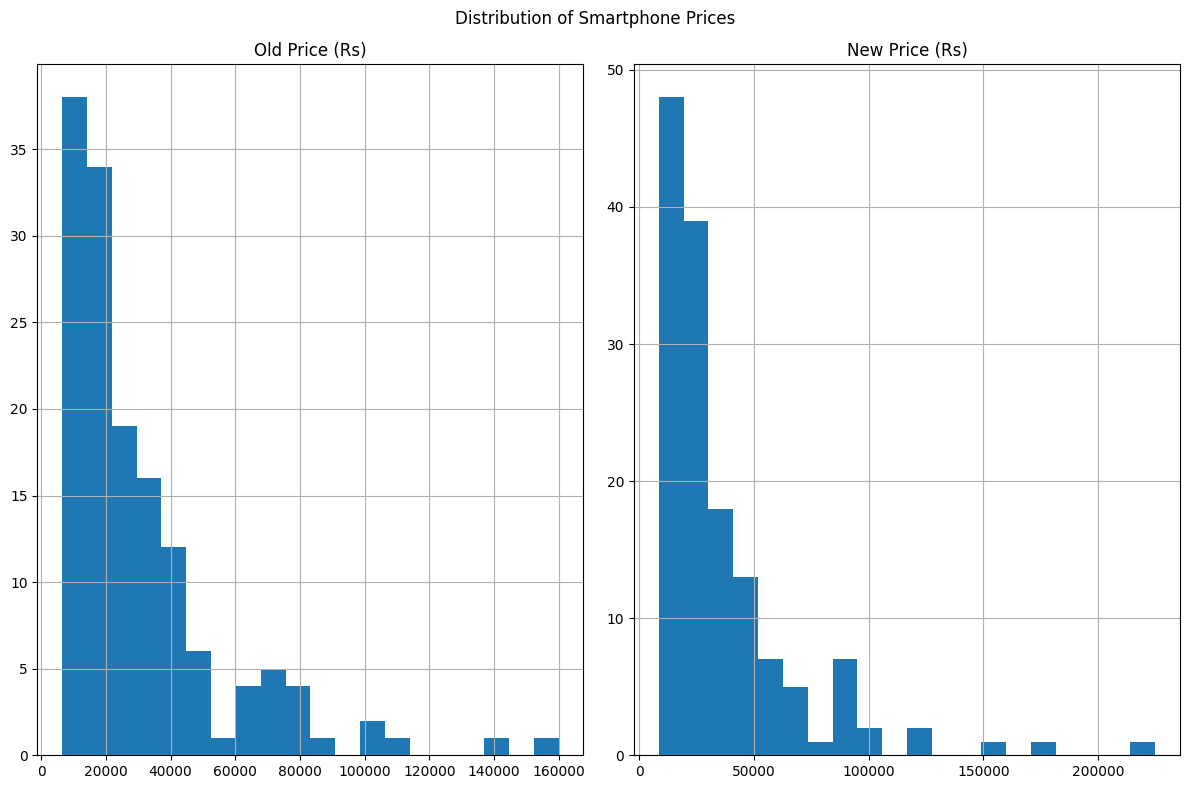

In [20]:
#Data Visualization (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# 1. Histogram
numeric_df.hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Smartphone Prices")
plt.tight_layout()
plt.show()

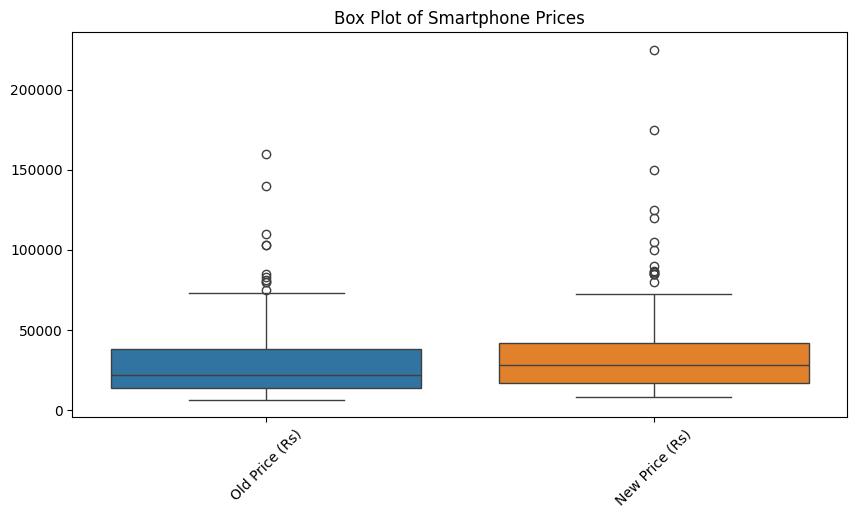

In [21]:
# 2. Box Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=numeric_df)
plt.title("Box Plot of Smartphone Prices")
plt.xticks(rotation=45)
plt.show()

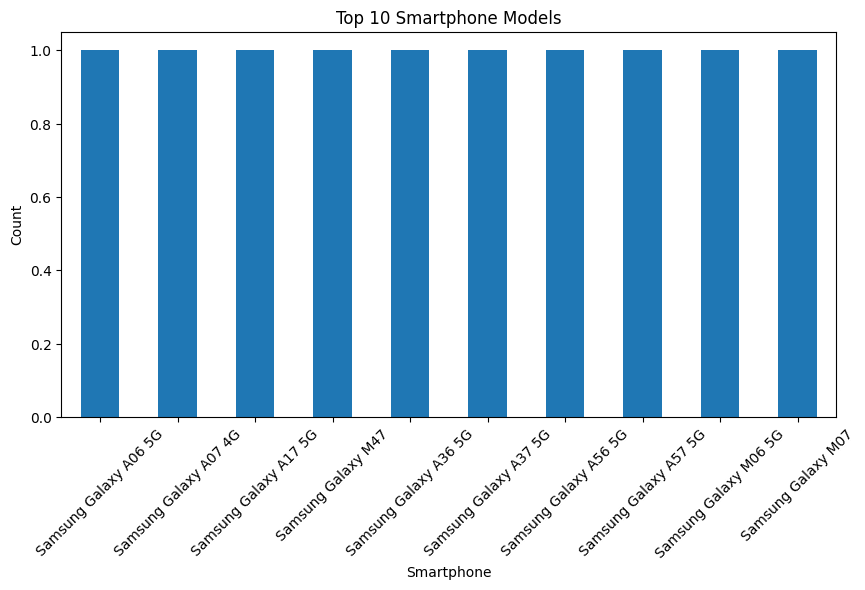

In [22]:
# 3. Bar Chart
plt.figure(figsize=(10, 5))
df.iloc[:, 0].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Smartphone Models")
plt.xlabel("Smartphone")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

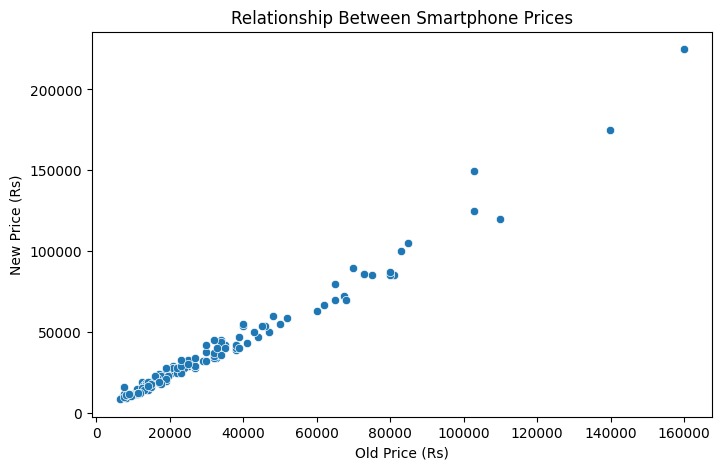

In [23]:
# 4. Scatter Plot
if len(price_columns) >= 2:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=df,
        x=price_columns[0],
        y=price_columns[1]
    )
    plt.title("Relationship Between Smartphone Prices")
    plt.xlabel(price_columns[0])
    plt.ylabel(price_columns[1])
    plt.show()

,Old Price (Rs),New Price (Rs)
Old Price (Rs),1.00000,0.98704
New Price (Rs),0.98704,1.00000


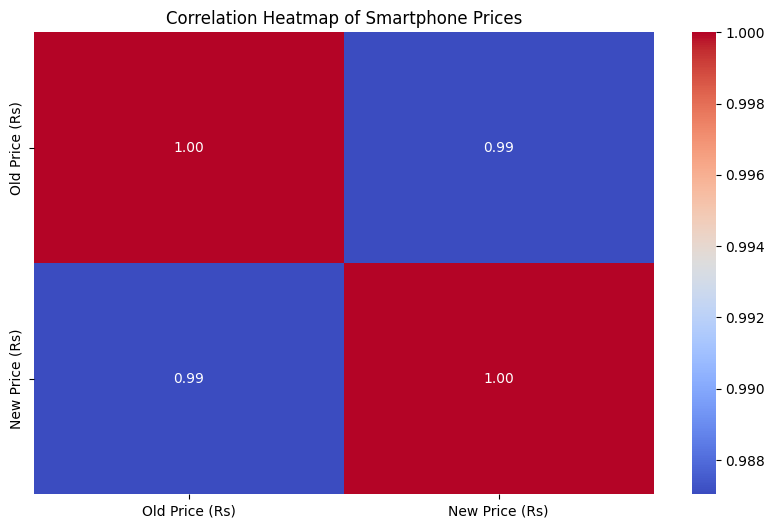

,Old Price (Rs),New Price (Rs)
Old Price (Rs),6.737472e+08,8.223754e+08
New Price (Rs),8.223754e+08,1.030325e+09


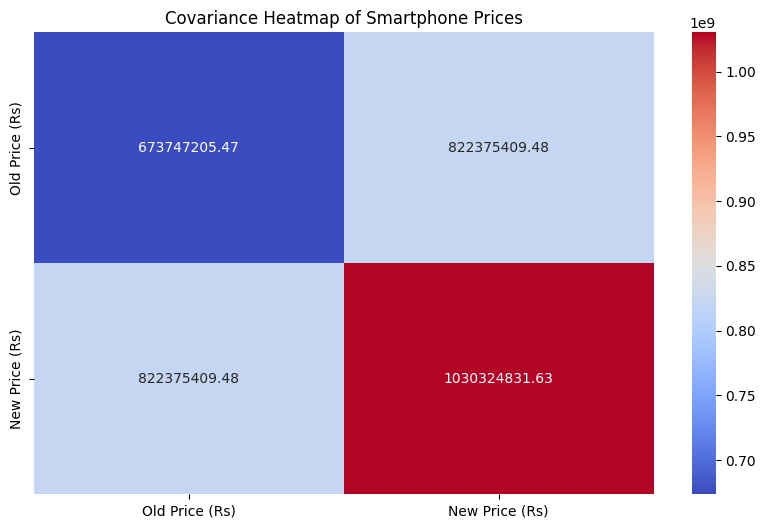

In [24]:
#Correlation and Covariance Analysis
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Correlation Matrix
correlation = numeric_df.corr()

display(correlation)

# Correlation Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Smartphone Prices")
plt.show()

# Covariance Matrix
covariance = numeric_df.cov()

display(covariance)

# Covariance Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(covariance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Covariance Heatmap of Smartphone Prices")
plt.show()

In [25]:
#Pearson and Spearman Correlation with Hypothesis Testing
from scipy.stats import pearsonr, spearmanr

# Select numerical price columns
price_data = df[price_columns].dropna()

if len(price_columns) >= 2 and len(price_data) >= 3:

    x = price_data[price_columns[0]]
    y = price_data[price_columns[1]]

    # Pearson Correlation
    pearson_corr, pearson_p = pearsonr(x, y)

    # Spearman Correlation
    spearman_corr, spearman_p = spearmanr(x, y)

    results = pd.DataFrame({
        "Test": ["Pearson", "Spearman"],
        "Correlation": [pearson_corr, spearman_corr],
        "P-Value": [pearson_p, spearman_p]
    })

    results["Decision"] = results["P-Value"].apply(
        lambda p: "Reject H0" if p < 0.05 else "Fail to Reject H0"
    )

    display(results)

else:
    display("At least two price columns and three complete records are required.")

,Test,Correlation,P-Value,Decision
0,Pearson,0.98704,1.596836e-115,Reject H0
1,Spearman,0.98664,1.379537e-114,Reject H0


In [26]:
#Confidence Interval Estimation for Smartphone Prices
from scipy import stats
import numpy as np
import pandas as pd

# Select the new price column
price = df[price_columns[-1]].dropna()

# Sample statistics
n = len(price)
mean = price.mean()
std = price.std()
se = std / np.sqrt(n)

# 95% Confidence Interval using t-distribution
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=n-1,
    loc=mean,
    scale=se
)

results = pd.DataFrame({
    "Statistic": [
        "Sample Size",
        "Mean Price",
        "Standard Deviation",
        "Standard Error",
        "Lower Confidence Limit",
        "Upper Confidence Limit"
    ],
    "Value": [
        n,
        mean,
        std,
        se,
        confidence_interval[0],
        confidence_interval[1]
    ]
})

display(results)

,Statistic,Value
0,Sample Size,145.000000
1,Mean Price,36698.379310
2,Standard Deviation,32098.673362
3,Standard Error,2665.649732
4,Lower Confidence Limit,31429.522516
5,Upper Confidence Limit,41967.236105


In [27]:
#One-Sample t-Test for Smartphone Prices
from scipy.stats import ttest_1samp

# Select smartphone price column
price = df[price_columns[-1]].dropna()

# Hypothesized population mean
hypothesized_mean = 20000

# Perform One-Sample t-Test
t_statistic, p_value = ttest_1samp(
    price,
    popmean=hypothesized_mean
)

# Display results
results = pd.DataFrame({
    "Statistic": [
        "Sample Size",
        "Sample Mean",
        "Hypothesized Mean",
        "T-Statistic",
        "P-Value"
    ],
    "Value": [
        len(price),
        price.mean(),
        hypothesized_mean,
        t_statistic,
        p_value
    ]
})

display(results)

# Hypothesis Testing Decision
if p_value < 0.05:
    display("Reject H0: Mean smartphone price is significantly different from ₹20,000.")
else:
    display("Fail to Reject H0: Insufficient evidence that mean smartphone price differs from ₹20,000.")

,Statistic,Value
0,Sample Size,1.450000e+02
1,Sample Mean,3.669838e+04
2,Hypothesized Mean,2.000000e+04
3,T-Statistic,6.264281e+00
4,P-Value,4.080992e-09


'Reject H0: Mean smartphone price is significantly different from ₹20,000.'

In [39]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Feature Scaling
from sklearn.preprocessing import StandardScaler

# Regression Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Model Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv('smartphone_prices.csv')

# One-Hot Encoding for Model
df = pd.get_dummies(df, columns=['Model'], drop_first=True, dtype=int)

# Independent Variables (Inputs)
X = df.drop('New Price (Rs)', axis=1)

# Dependent Variable (Output)
y = df['New Price (Rs)']

print("X:")
print(X.head())

print("\ny:")
print(y.head())

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X:
   Old Price (Rs)  Model_AI+ Nova 2 Ultra  Model_AI+ Nova 5G  \
0           10499                       0                  0   
1           13899                       0                  0   
2           18999                       0                  0   
3           32999                       0                  0   
4           32499                       0                  0   

   Model_AI+ Pulse 2  Model_Lava Agni 4  Model_Lava Blaze Dragon  \
0                  0                  0                        0   
1                  0                  0                        0   
2                  0                  0                        0   
3                  0                  0                        0   
4                  0                  0                        0   

   Model_Lava Blaze Duo 3  Model_Lava Play Max  Model_Lava Shark 5G  \
0                       0                    0                    0   
1                       0                    0               

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 116
Testing samples: 29


In [41]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [42]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_pred = linear_model.predict(
    X_test_scaled
)

print("Multiple Linear Regression")
print("=" * 50)
print("Intercept:", linear_model.intercept_)

Multiple Linear Regression
Intercept: 37253.38793103448


In [43]:
ridge_model = Ridge(alpha=5.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

ridge_pred = ridge_model.predict(
    X_test_scaled
)

print("Ridge Regression")
print("=" * 50)
print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))

Ridge Regression
Alpha: 5.0
Intercept: 37253.39


In [44]:
lasso_model = Lasso(alpha=0.1, max_iter=100000)

lasso_model.fit(
    X_train_scaled,
    y_train
)

lasso_pred = lasso_model.predict(
    X_test_scaled
)

print("Lasso Regression")
print("=" * 50)
print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))



Lasso Regression
Alpha: 0.1
Intercept: 37253.39


In [45]:
tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(X_test)

print("Decision Tree Regression")
print("=" * 50)
print("Maximum Depth:", tree_model.max_depth)



Decision Tree Regression
Maximum Depth: 3


In [46]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest Regression")
print("=" * 50)
print("Number of Trees:", forest_model.n_estimators)
print("Maximum Depth:", forest_model.max_depth)

Random Forest Regression
Number of Trees: 100
Maximum Depth: 3


In [47]:
predictions = {
    'Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
}

results = []

for model_name, prediction in predictions.items():
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    results.append([
        model_name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2']
)

print("Model Performance Comparison")
print("=" * 70)
print(results_df.round(2))

Model Performance Comparison
                      Model      MAE           MSE      RMSE    R2
0         Linear Regression  7681.15  1.214416e+08  11020.05  0.77
1          Ridge Regression  7529.11  1.056173e+08  10277.03  0.80
2          Lasso Regression  3475.14  2.459355e+07   4959.19  0.95
3  Decision Tree Regression  3269.18  1.506812e+07   3881.77  0.97
4  Random Forest Regression  3335.55  2.016112e+07   4490.11  0.96


In [48]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
})

print("Actual vs Predicted Values")

print(
    comparison.round(2).to_string(index=False)
)

Actual vs Predicted Values
 Actual  Linear Regression  Ridge Regression  Lasso Regression  Decision Tree Regression  Random Forest Regression
  23999           17988.04          26317.55          21290.67                  25440.18                  22770.35
  29999           23977.07          31379.82          31107.63                  25440.18                  27041.79
  20999           19485.30          27583.12          23744.91                  25440.18                  24467.93
  89900           57591.29          59792.43          86206.54                  83910.44                  73918.75
  22999           18736.67          26950.34          22517.79                  25440.18                  23525.48
  15499           14619.20          23470.03          15768.63                  13701.73                  14011.71
  15999           10876.06          20306.11           9633.03                  13701.73                  13766.68
  18499           17988.04          26317.55         

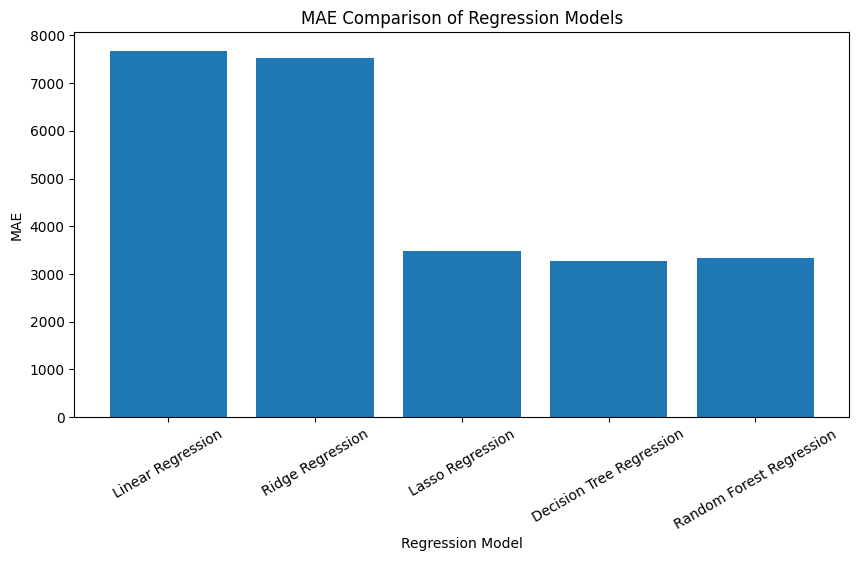

In [49]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['MAE']
)

plt.xlabel("Regression Model")
plt.ylabel("MAE")
plt.title("MAE Comparison of Regression Models")
plt.xticks(rotation=30)
plt.show()

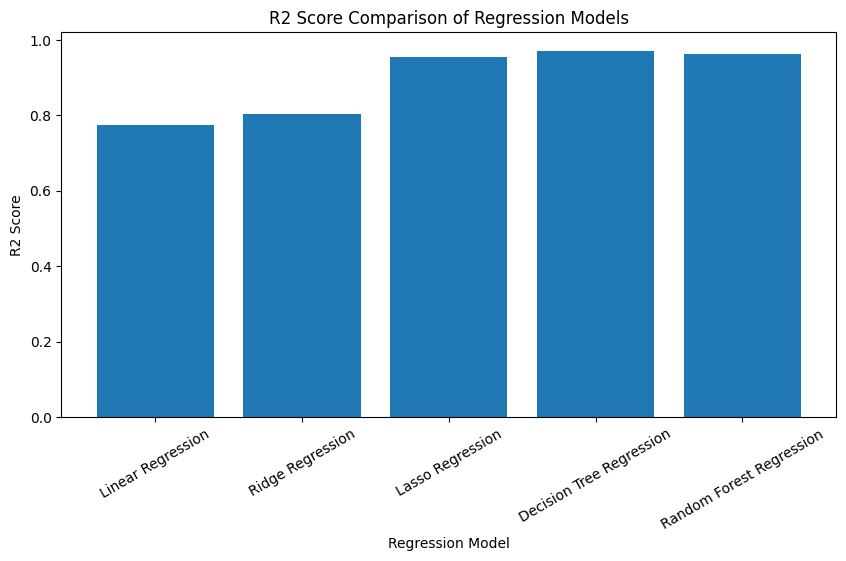

In [50]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['R2']
)

plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison of Regression Models")
plt.xticks(rotation=30)
plt.show()

In [51]:
model = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree Regression": tree_model,
    "Random Forest Regression": forest_model
}

best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

best_model = model[best_model_name]

print("Best Model:", best_model_name)

Best Model: Decision Tree Regression


In [52]:
import joblib

joblib.dump(
    best_model,
    'best_smartphone_model.pkl'
)

joblib.dump(
    scaler,
    'scaler.pkl'
)

joblib.dump(
    X.columns.tolist(),
    'feature_columns.pkl'
)

joblib.dump(
    best_model_name,
    'best_model_name.pkl'
)

print("Best model saved successfully.")
print("Scaler saved successfully.")
print("Feature columns saved successfully.")

Best model saved successfully.
Scaler saved successfully.
Feature columns saved successfully.


In [53]:
model = joblib.load('best_smartphone_model.pkl')

scaler = joblib.load('scaler.pkl')

feature_columns = joblib.load('feature_columns.pkl')

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [54]:
from google.colab import files

files.download('best_smartphone_model.pkl')
files.download('scaler.pkl')
files.download('feature_columns.pkl')
files.download('best_model_name.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>